# Lecture 3 — Grover & Amplitude Amplification (UnitaryLab companion)

This notebook demonstrates Grover's search on $n=4$ qubits ($N=16$ items, one marked
item $x_0=5=|0101\rangle$) using the UnitaryLab simulator (v1.1.4). Run the cells top
to bottom.

Contents:
1. Deutsch–Jozsa and Bernstein–Vazirani (one quantum query)
2. The oracle (phase flip on the marked item) and the diffusion operator
3. **Example 3.25** — a fully worked run ($N=16$, $x_0=5$): probability per iteration, peak at $k=3$
4. **Example 3.28** — running Grover in practice: choose $k^\ast$ from $N$, measure, verify
5. **Example 3.29** — a search whose solution we do not know (invert a function)

In [1]:
import numpy as np
from unitarylab.core import Circuit

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
%matplotlib inline

n = 4
N = 2**n            # 16 items
marked = 5          # x0 = |0101> = 5

## 1. Deutsch–Jozsa and Bernstein–Vazirani (one quantum query)

Before Grover, the chapter's first algorithms show a clean quantum advantage with a *single* query. Both use the same circuit — $H^{\otimes n}$, a **phase oracle** $|x\rangle\mapsto(-1)^{f(x)}|x\rangle$, then $H^{\otimes n}$ — and read the answer straight off the measurement.

- **Deutsch–Jozsa:** $f$ is promised constant or balanced; the all-zeros outcome occurs with probability $1$ iff $f$ is *constant*.
- **Bernstein–Vazirani:** $f_s(x)=s\cdot x$; the phase oracle is a $Z$ on each qubit where $s_i=1$, and the measurement returns the hidden string $s$ in **one** query (classically $n$ are needed).

In [2]:
# Phase oracle (-1)^{f(x)} applied in place; H^n before and after, then read the outcome.
def run_hoh(oracle, nq):
    qc = Circuit(nq)
    for q in range(nq): qc.h(q)
    oracle(qc)
    for q in range(nq): qc.h(q)
    return np.abs(qc.execute(backend='numpy', dtype=np.complex128).state) ** 2

n_dj = 3   # a 3-qubit instance for these one-query demos (independent of the Grover n below)
# --- Deutsch-Jozsa: constant vs balanced ---
P_const = run_hoh(lambda qc: None, n_dj)        # f(x)=0 (constant): phase oracle = identity
P_bal   = run_hoh(lambda qc: qc.z(0), n_dj)     # f(x)=x_0 (balanced): phase oracle = Z on qubit 0
print(f'Deutsch-Jozsa  constant: P(000) = {P_const[0]:.3f}  -> constant')
print(f'Deutsch-Jozsa  balanced: P(000) = {P_bal[0]:.3f}  -> balanced')
assert P_const[0] > 0.999 and P_bal[0] < 1e-9

# --- Bernstein-Vazirani: recover the hidden string s in one query ---
def bv_recover(s, nq):
    def oracle(qc):
        for q in range(nq):
            if (s >> q) & 1: qc.z(q)         # (-1)^{s.x} = product of Z over the s-qubits
    return int(np.argmax(run_hoh(oracle, nq)))

print('\nBernstein-Vazirani (1 query each):')
for s in [0b101, 0b110, 0b011]:
    got = bv_recover(s, n_dj)
    print(f'  hidden s = {s:0{n_dj}b}  ->  recovered {got:0{n_dj}b}')
    assert got == s
print('\nAll one-query algorithms verified.')

Deutsch-Jozsa  constant: P(000) = 1.000  -> constant
Deutsch-Jozsa  balanced: P(000) = 0.000  -> balanced

Bernstein-Vazirani (1 query each):
  hidden s = 101  ->  recovered 101
  hidden s = 110  ->  recovered 110
  hidden s = 011  ->  recovered 011

All one-query algorithms verified.


## 2. Oracle and diffusion

**Oracle** $O_f$ flips the sign of the amplitude of the marked state:
$O_f|x\rangle = (-1)^{[x=\text{marked}]}|x\rangle$. We implement it as a
multi-controlled-$Z$: surround an `mcx` (with the last qubit as target) by
Hadamards on that target so the controlled-$X$ becomes a controlled-$Z$, and use
$X$ gates to select the marked control pattern.

**Diffusion** $D = 2|s\rangle\langle s| - I$ reflects about the uniform
superposition $|s\rangle = H^{\otimes n}|0\rangle$. It is
$H^{\otimes n}(2|0\rangle\langle0| - I)H^{\otimes n}$, and the middle reflection
is again a multi-controlled-$Z$ about $|0\dots0\rangle$.

In [3]:
def apply_mcz(qc, qubits):
    '''Multi-controlled Z on the given qubits (phase flip of the all-ones state).'''
    *controls, target = qubits
    qc.h(target)
    qc.mcx(controls, target)
    qc.h(target)

def apply_oracle(qc, marked, n):
    '''Phase-flip the |marked> basis state.'''
    bits = [(marked >> q) & 1 for q in range(n)]   # bit for qubit q (q=0 is LSB)
    for q in range(n):
        if bits[q] == 0:
            qc.x(q)
    apply_mcz(qc, list(range(n)))
    for q in range(n):
        if bits[q] == 0:
            qc.x(q)

def apply_diffusion(qc, n):
    for q in range(n): qc.h(q)
    for q in range(n): qc.x(q)
    apply_mcz(qc, list(range(n)))
    for q in range(n): qc.x(q)
    for q in range(n): qc.h(q)

## Example 3.25 — a fully worked run ($N=16$, $x_0=5$)

We build the full Grover circuit for $k$ iterations, read the exact statevector, and
record the probability of the marked item $x_0=5=|0101\rangle$. For $N=16$, $M=1$ the
amplitudes are clean fractions, and the success probability climbs to its peak at
$k=3$ and then *falls* as iterations $k=4,5$ **over-rotate** past the target.

In [4]:
from fractions import Fraction as Fr
n, N, marked = 4, 16, 5                        # x0 = |0101>

def grover_success_prob(k, marked, n):
    qc = Circuit(n, name=f'grover_k{k}')
    for q in range(n): qc.h(q)                 # uniform superposition
    for _ in range(k):
        apply_oracle(qc, marked, n)
        apply_diffusion(qc, n)
    probs = qc.execute(backend='numpy', dtype=np.complex128).probabilities
    return probs.get(format(marked, f'0{n}b'), 0.0)   # key reads q_{n-1}...q_0

# closed-form success probability p_k = sin^2((2k+1) arcsin(1/4)) at k = 0..5
exact = [Fr(1,16), Fr(121,256), Fr(3721,4096), Fr(63001,65536),
         Fr(609961,1048576), Fr(2105401,16777216)]
ks = list(range(6))
succ = [grover_success_prob(k, marked, n) for k in ks]
for k, p, e in zip(ks, succ, exact):
    tag = '  <- optimum' if k == 3 else ('  (over-rotated)' if k > 3 else '')
    print(f'k={k}: P(marked) = {p:.4f}   exact {str(e):>18} = {float(e):.4f}{tag}')
    assert abs(p - float(e)) < 1e-9

peak_k = int(np.argmax(succ))
print('\npeak at k =', peak_k, 'with P =', round(succ[peak_k], 4))
assert peak_k == 3 and succ[3] > 0.96, 'For N=16 the optimum is k=3 with P>0.96'
assert succ[4] < succ[3] and succ[5] < succ[4], 'k=4,5 over-rotate (probability falls)'
print('verified: peak at k=3 (0.961); k=4,5 over-rotate, matching the closed form')

k=0: P(marked) = 0.0625   exact               1/16 = 0.0625
k=1: P(marked) = 0.4727   exact            121/256 = 0.4727
k=2: P(marked) = 0.9084   exact          3721/4096 = 0.9084
k=3: P(marked) = 0.9613   exact        63001/65536 = 0.9613  <- optimum
k=4: P(marked) = 0.5817   exact     609961/1048576 = 0.5817  (over-rotated)
k=5: P(marked) = 0.1255   exact   2105401/16777216 = 0.1255  (over-rotated)

peak at k = 3 with P = 0.9613
verified: peak at k=3 (0.961); k=4,5 over-rotate, matching the closed form


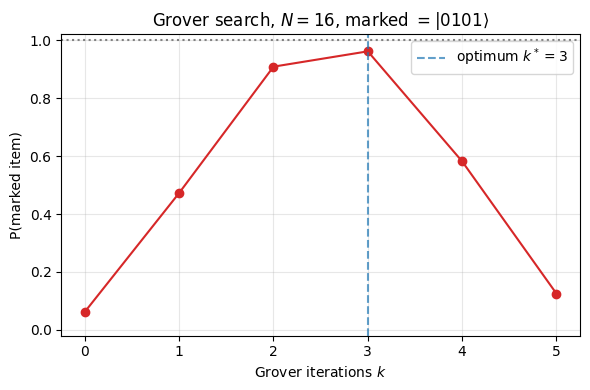

In [5]:
plt.figure(figsize=(6,4))
plt.plot(ks, succ, 'o-', color='C3')
plt.axvline(3, ls='--', color='C0', alpha=0.7, label='optimum $k^*=3$')
plt.axhline(1.0, ls=':', color='gray')
plt.xlabel('Grover iterations $k$'); plt.ylabel('P(marked item)')
plt.title(f'Grover search, $N={N}$, marked $=|{format(marked, f"0{n}b")}\\rangle$')
plt.ylim(-0.02, 1.02); plt.grid(True, alpha=0.3); plt.legend()
plt.tight_layout(); plt.show()

## Example 3.28 — running Grover in practice (choose $k^\ast$ from $N$, measure, verify)

We never know $x_0$ in advance. The one thing we *do* know is $N$ (and here $M=1$),
which already fixes the optimal iteration count
$k^\ast=\lfloor\tfrac{\pi}{4}\sqrt N\rfloor=3$ — it depends only on $N$, not on *which*
item is marked. The practical recipe is: run $k^\ast=3$ iterations, **measure** a
candidate $y$, and **verify** it with one evaluation of the predicate $f$. A wrong
guess is detected and costs only a repeat, so the expected number of attempts is
$1/p_3\approx1.04$ — almost always the first.

In [6]:
k_star = int(np.floor(np.pi/4 * np.sqrt(N)))      # uses only N (and M=1), not x0
print(f'optimal iterations k* = floor((pi/4) sqrt(N)) = {k_star}')

# run Grover for k* and read out the measurement distribution over the 16 items
qc = Circuit(n)
for q in range(n): qc.h(q)
for _ in range(k_star):
    apply_oracle(qc, marked, n)
    apply_diffusion(qc, n)
probs = qc.execute(backend='numpy', dtype=np.complex128).probabilities
dist = np.array([probs.get(format(i, f'0{n}b'), 0.0) for i in range(N)])
dist = dist / dist.sum()
p_succ = dist[marked]
print(f'single-run success probability p = {p_succ:.4f}  (theory 63001/65536 = {63001/65536:.4f})')

def f(y):                                         # the verifier/predicate: 1 iff y solves the search
    return int(y == marked)

rng = np.random.default_rng(0)
def one_search():                                 # Las Vegas loop: measure, verify, repeat
    attempts = 0
    while True:
        attempts += 1
        y = int(rng.choice(N, p=dist))            # measure the k*-iteration state
        if f(y):                                  # one query to the verifier
            return attempts
trials = 20000
mean_attempts = float(np.mean([one_search() for _ in range(trials)]))
print(f'empirical mean attempts = {mean_attempts:.3f}   (theory 1/p = {1/p_succ:.3f})')
print(f'expected queries ~ attempts*(k*+1) = {mean_attempts*(k_star+1):.2f}   '
      f'vs classical average {N//2}')
assert abs(mean_attempts - 1/p_succ) < 0.1
print('verified: k*=3 chosen from N alone; measure + one-query verify finds x0 in ~1 attempt')

optimal iterations k* = floor((pi/4) sqrt(N)) = 3
single-run success probability p = 0.9613  (theory 63001/65536 = 0.9613)
empirical mean attempts = 1.040   (theory 1/p = 1.040)
expected queries ~ attempts*(k*+1) = 4.16   vs classical average 8
verified: k*=3 chosen from N alone; measure + one-query verify finds x0 in ~1 attempt


## Example 3.29 — a search whose solution we do not know (invert a function)

The oracle in §2 phase-flips a *known* `marked` string — fine for illustration, but
in a real search we do not know $x_0$. Here we compile the oracle from a
**verifier**: given an efficiently computable, invertible 4-bit function $g$ and a
known target $t$, we mark the (unknown) solution $x_0=g^{-1}(t)$ by **compute $g$ →
mark $t$ → uncompute** on a clean ancilla register (`apply_mcz` from §2 supplies the
multi-controlled $Z$). Grover then recovers $x_0$ using only $g$ and $t$ — never $x_0$
itself. (We pick $t=g(5)$ so the hidden solution happens to be $x_0=5$, but the
circuit never uses that fact.)

In [7]:
# Verifier: f(x) = 1 iff g(x) == t, for an invertible 4-bit function g.
def g(x):
    x0, x1, x2, x3 = x & 1, (x >> 1) & 1, (x >> 2) & 1, (x >> 3) & 1
    a0 = x0
    a1 = x0 ^ x1
    a2 = x2 ^ (x0 & x1)
    a3 = x3 ^ (x1 & x2)
    return a0 | (a1 << 1) | (a2 << 2) | (a3 << 3)

t = g(5)                                              # target published by someone who chose x0=5
x0_star = next(x for x in range(N) if g(x) == t)      # computed only to CHECK the result
print(f'target t = {t:0{n}b}; solution g^-1(t) = {x0_star} = {x0_star:0{n}b}',
      '(never used to build the oracle)')

def apply_Ug(qc, d, a):                               # |x>|0> -> |x>|g(x)>
    qc.cx(d[0], a[0])                                 # a0 = x0
    qc.cx(d[0], a[1]); qc.cx(d[1], a[1])              # a1 = x0 ^ x1
    qc.cx(d[2], a[2]); qc.mcx([d[0], d[1]], a[2])     # a2 = x2 ^ (x0 & x1)
    qc.cx(d[3], a[3]); qc.mcx([d[1], d[2]], a[3])     # a3 = x3 ^ (x1 & x2)

def apply_Ug_dag(qc, d, a):                           # inverse: reverse the gate order
    qc.mcx([d[1], d[2]], a[3]); qc.cx(d[3], a[3])
    qc.mcx([d[0], d[1]], a[2]); qc.cx(d[2], a[2])
    qc.cx(d[1], a[1]); qc.cx(d[0], a[1])
    qc.cx(d[0], a[0])

def oracle_from_verifier(qc, t, d, a):
    apply_Ug(qc, d, a)                                # 1. compute g(x) into the ancilla
    tb = [(t >> j) & 1 for j in range(len(a))]
    for j in range(len(a)):
        if tb[j] == 0: qc.x(a[j])                     # 2. mark the ancilla pattern == t
    apply_mcz(qc, a)
    for j in range(len(a)):
        if tb[j] == 0: qc.x(a[j])
    apply_Ug_dag(qc, d, a)                            # 3. uncompute -> ancilla back to |0>

def apply_diffusion_on(qc, qubits):
    for q in qubits: qc.h(q)
    for q in qubits: qc.x(q)
    apply_mcz(qc, qubits)
    for q in qubits: qc.x(q)
    for q in qubits: qc.h(q)

def grover_verifier(k):
    data, anc = [0, 1, 2, 3], [4, 5, 6, 7]            # 4 data qubits + 4 clean ancillas
    qc = Circuit(8, name=f'grover_verifier_k{k}')
    for q in data: qc.h(q)
    for _ in range(k):
        oracle_from_verifier(qc, t, data, anc)
        apply_diffusion_on(qc, data)
    p = np.abs(qc.execute(backend='numpy', dtype=np.complex128).state) ** 2
    P_x0     = sum(p[i] for i in range(2**8) if (i & 15) == x0_star and (i >> 4) == 0)
    anc_leak = sum(p[i] for i in range(2**8) if (i >> 4) != 0)        # should be ~0
    return P_x0, anc_leak

for k in range(6):
    P, leak = grover_verifier(k)
    print(f'k={k}: P(find x0*) = {P:.4f}   ancilla leakage = {leak:.1e}')

P3, leak3 = grover_verifier(3)
assert P3 > 0.95,    'k=3 should find the solution with probability > 0.95'
assert leak3 < 1e-9, 'ancillas must be uncomputed (no leakage back into the data)'
assert g(x0_star) == t, 'sanity: the recovered string really is a solution'
print(f'\nGrover recovered x0 = {x0_star:0{n}b} with probability {P3:.3f}, using only g and t.')

target t = 0111; solution g^-1(t) = 5 = 0101 (never used to build the oracle)
k=0: P(find x0*) = 0.0625   ancilla leakage = 0.0e+00
k=1: P(find x0*) = 0.4727   ancilla leakage = 0.0e+00
k=2: P(find x0*) = 0.9084   ancilla leakage = 0.0e+00
k=3: P(find x0*) = 0.9613   ancilla leakage = 0.0e+00
k=4: P(find x0*) = 0.5817   ancilla leakage = 0.0e+00
k=5: P(find x0*) = 0.1255   ancilla leakage = 0.0e+00

Grover recovered x0 = 0101 with probability 0.961, using only g and t.


### Your turn
- Change `marked` to a different 4-bit item (0–15) and confirm the peak stays at $k=3$.
- Mark **two** items and rebuild the oracle to flip both; the optimal $k$ drops to
  about $\frac{\pi}{4}\sqrt{16/2}\approx 2.2 \Rightarrow k=2$.
- In Example 3.28, raise `trials` and watch the empirical mean attempts converge to $1/p_3$.
- In Example 3.29, change $t$ (hence the hidden $x_0$) and confirm Grover still finds it from $g,t$ alone.